In [1]:
# ================================================
# Notebook 09: Análisis Lingüístico — Corpus Ecuatoriano
# Autor: Steeven Quezada
# Técnica: LDA (Latent Dirichlet Allocation) con sklearn
# Dataset: Corpus Ecuador Chequea (1,500+ verificaciones)
# ================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
import re
import nltk
import joblib

warnings.filterwarnings('ignore')

from sklearn.decomposition import LatentDirichletAllocation
from sklearn.feature_extraction.text import CountVectorizer
from nltk.corpus import stopwords

# Cargar corpus ecuatoriano
df = pd.read_csv('../data/external/corpus_ecuador_final.csv')
print(f"Corpus cargado: {len(df):,} artículos")
print(f"Columnas: {df.columns.tolist()}")
print(f"\nDistribución:")
print(df['etiqueta'].value_counts())

Corpus cargado: 1,543 artículos
Columnas: ['titulo', 'contenido', 'etiqueta', 'fecha', 'url', 'label_binario']

Distribución:
etiqueta
FALSO        1088
CIERTO        221
ENGAÑOSO      168
IMPRECISO      64
VERDADERO       2
Name: count, dtype: int64


In [2]:
# ================================================
# PASO 1: PREPROCESAMIENTO PARA LDA
# ================================================
nltk.download('stopwords', quiet=True)

# Stopwords en español
stop_es = set(stopwords.words('spanish'))

# Agregar stopwords específicas del dominio
stop_custom = {
    'ecuador', 'chequea', 'verificación', 'publicación',
    'información', 'según', 'afirma', 'dice', 'dijo',
    'señala', 'indica', 'asegura', 'contenido', 'dato',
    'imagen', 'video', 'post', 'facebook', 'twitter',
    'redes', 'sociales', 'viral', 'circula', 'usuarios',
    'también', 'además', 'sino', 'aunque', 'embargo'
}
stop_words = stop_es.union(stop_custom)

def limpiar_texto_es(texto):
    """Limpieza básica para español."""
    if not isinstance(texto, str):
        return ''
    texto = texto.lower()
    texto = re.sub(r'http\S+|www\S+', '', texto)
    texto = re.sub(r'[^a-záéíóúüñ\s]', '', texto)
    texto = re.sub(r'\s+', ' ', texto).strip()
    # Filtrar stopwords y palabras cortas
    tokens = [w for w in texto.split() 
              if w not in stop_words and len(w) > 3]
    return ' '.join(tokens)

print("Preprocesando textos en español...")
df['texto_lda'] = df['contenido'].apply(limpiar_texto_es)

# Verificar
vacios = (df['texto_lda'].str.strip() == '').sum()
print(f"✓ Preprocesamiento completado")
print(f"  Textos vacíos: {vacios}")
print(f"\nEjemplo:")
print(f"Original: {df['contenido'].iloc[0][:150]}")
print(f"Limpio:   {df['texto_lda'].iloc[0][:150]}")

Preprocesando textos en español...
✓ Preprocesamiento completado
  Textos vacíos: 0

Ejemplo:
Original: Una publicación en TikTok asegura que se encuentran abiertas las matrículas gratuitas en la modalidad semipresencial del Ministerio de Educación para 
Limpio:   tiktok encuentran abiertas matrículas gratuitas modalidad semipresencial ministerio educación culminar escuela colegio bien institución cuenta program


In [3]:
# ================================================
# PASO 2: VECTORIZACIÓN Y ENTRENAMIENTO LDA
# ================================================

# Vectorizar con CountVectorizer
print("Vectorizando corpus...")
vectorizer = CountVectorizer(
    max_features=2000,   # top 2000 palabras más frecuentes
    min_df=5,            # aparece en al menos 5 documentos
    max_df=0.85,         # no más del 85% de documentos
    ngram_range=(1, 2)   # unigramas y bigramas
)

X = vectorizer.fit_transform(df['texto_lda'])
print(f"✓ Matriz documento-término: {X.shape}")

# Entrenar LDA
N_TOPICS = 8  # número de tópicos
print(f"\nEntrenando LDA con {N_TOPICS} tópicos...")

lda = LatentDirichletAllocation(
    n_components=N_TOPICS,
    random_state=42,
    max_iter=20,
    learning_method='batch'
)

lda.fit(X)
print(f"✓ LDA entrenado")

# Mostrar top palabras por tópico
feature_names = vectorizer.get_feature_names_out()

print(f"\n=== TOP 10 PALABRAS POR TÓPICO ===")
for topic_idx, topic in enumerate(lda.components_):
    top_words = [feature_names[i] 
                 for i in topic.argsort()[:-11:-1]]
    print(f"\nTópico {topic_idx + 1}:")
    print(f"  {' | '.join(top_words)}")

Vectorizando corpus...
✓ Matriz documento-término: (1543, 2000)

Entrenando LDA con 8 tópicos...
✓ LDA entrenado

=== TOP 10 PALABRAS POR TÓPICO ===

Tópico 1:
  noboa | presidente | daniel noboa | daniel | unidos | gobierno | país | méxico | seguridad | trump

Tópico 2:
  millones | país | gobierno | nacional | ministerio | años | personas | banco | social | acuerdo

Tópico 3:
  noboa | gonzález | gobierno | presidente | daniel noboa | daniel | nacional | luisa | luisa gonzález | país

Tópico 4:
  oficiales | fuentes | oficial | conclusión | tiktok | contexto | elementos | existe | trazabilidad | confiables

Tópico 5:
  consulta | popular | consulta popular | mundial | noviembre | fifa | partido | nebot | preguntas | constitución

Tópico 6:
  correa | caso | medio | rafael | rafael correa | fiscalía | encontró | glas | justicia | sido

Tópico 7:
  salud | cáncer | fuentes | casos | personas | mundial | riesgo | evidencia | estudio | alerta

Tópico 8:
  electoral | lasso | elecciones |

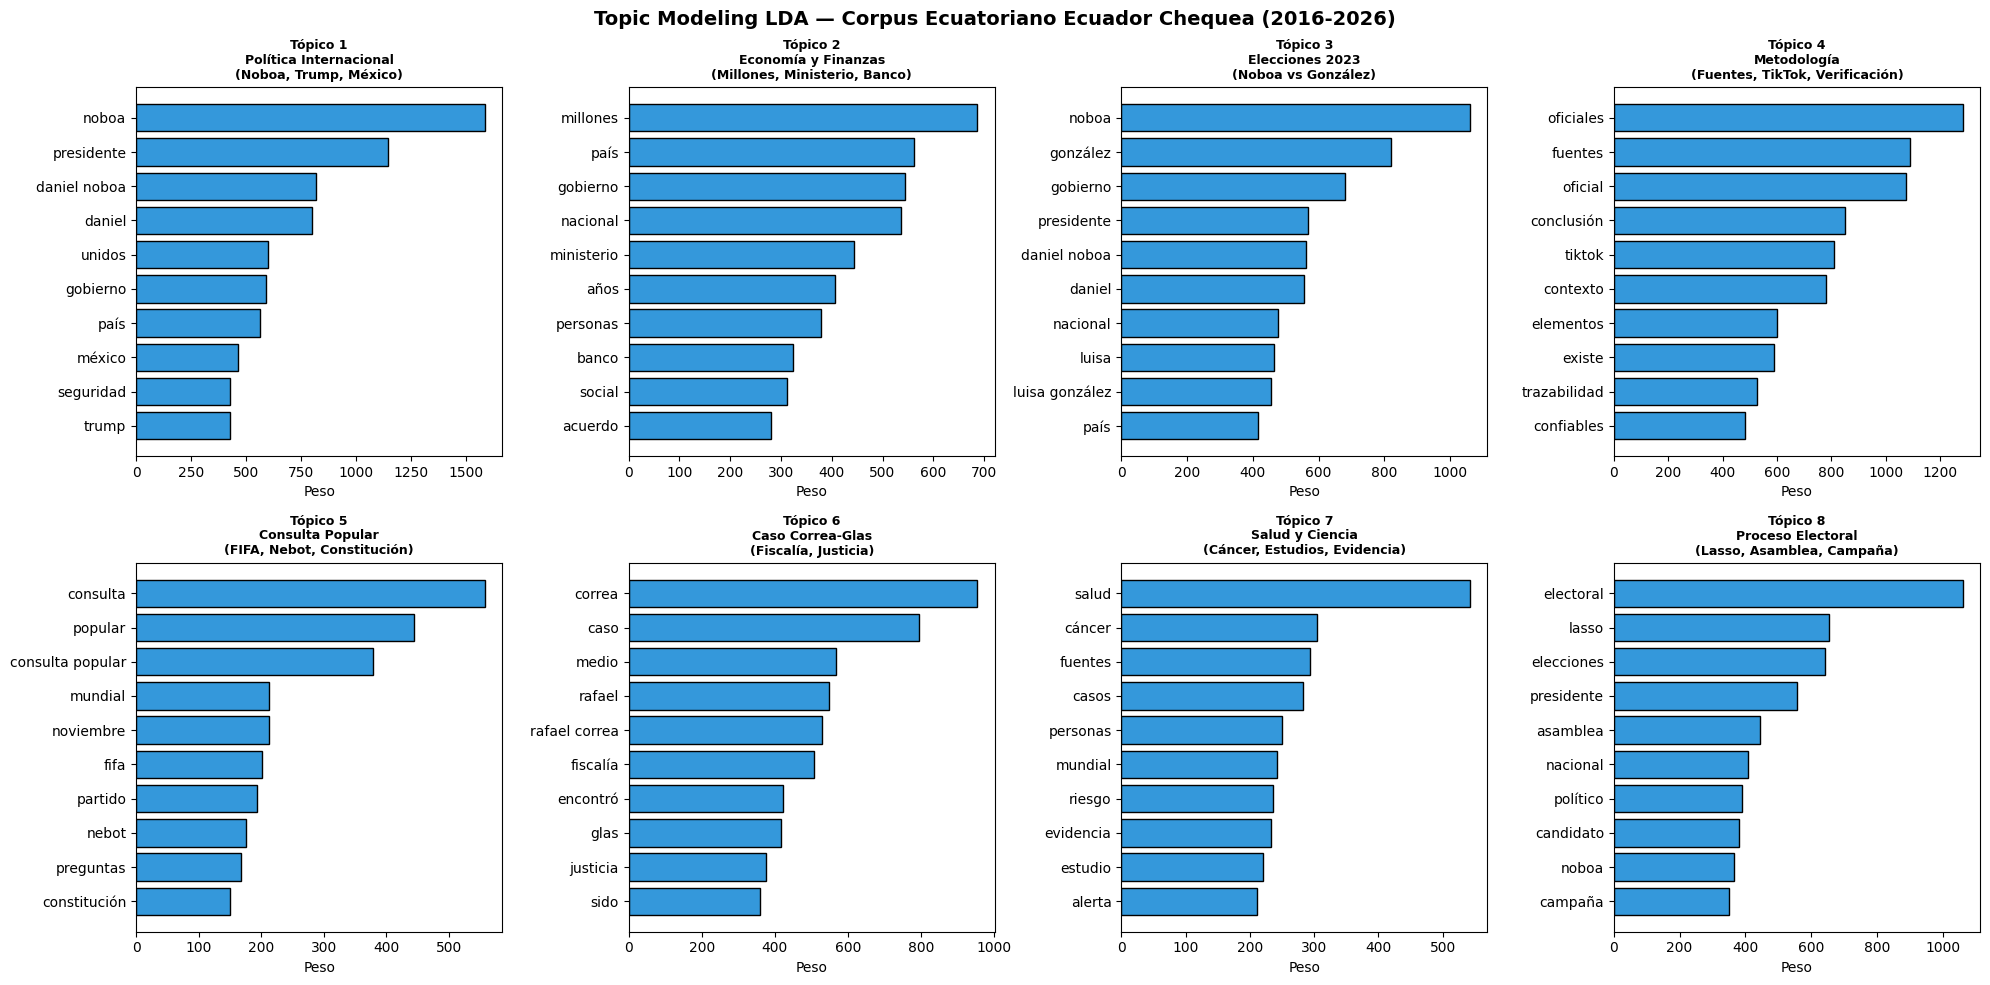

✓ Visualización guardada en reports/


In [4]:
# ================================================
# PASO 3: VISUALIZACIÓN DE TÓPICOS
# ================================================

# Nombres descriptivos para cada tópico
topico_nombres = {
    0: 'Política Internacional\n(Noboa, Trump, México)',
    1: 'Economía y Finanzas\n(Millones, Ministerio, Banco)',
    2: 'Elecciones 2023\n(Noboa vs González)',
    3: 'Metodología\n(Fuentes, TikTok, Verificación)',
    4: 'Consulta Popular\n(FIFA, Nebot, Constitución)',
    5: 'Caso Correa-Glas\n(Fiscalía, Justicia)',
    6: 'Salud y Ciencia\n(Cáncer, Estudios, Evidencia)',
    7: 'Proceso Electoral\n(Lasso, Asamblea, Campaña)',
}

fig, axes = plt.subplots(2, 4, figsize=(20, 10))
axes = axes.flatten()

for topic_idx, topic in enumerate(lda.components_):
    top_indices = topic.argsort()[:-11:-1]
    top_words   = [feature_names[i] for i in top_indices]
    top_weights = [topic[i] for i in top_indices]

    axes[topic_idx].barh(top_words[::-1], top_weights[::-1],
                         color='#3498DB', edgecolor='black')
    axes[topic_idx].set_title(f'Tópico {topic_idx+1}\n{topico_nombres[topic_idx]}',
                               fontweight='bold', fontsize=9)
    axes[topic_idx].set_xlabel('Peso')

plt.suptitle('Topic Modeling LDA — Corpus Ecuatoriano Ecuador Chequea (2016-2026)',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('../reports/16_lda_topicos_ecuador.png',
            dpi=150, bbox_inches='tight')
plt.show()
print("✓ Visualización guardada en reports/")

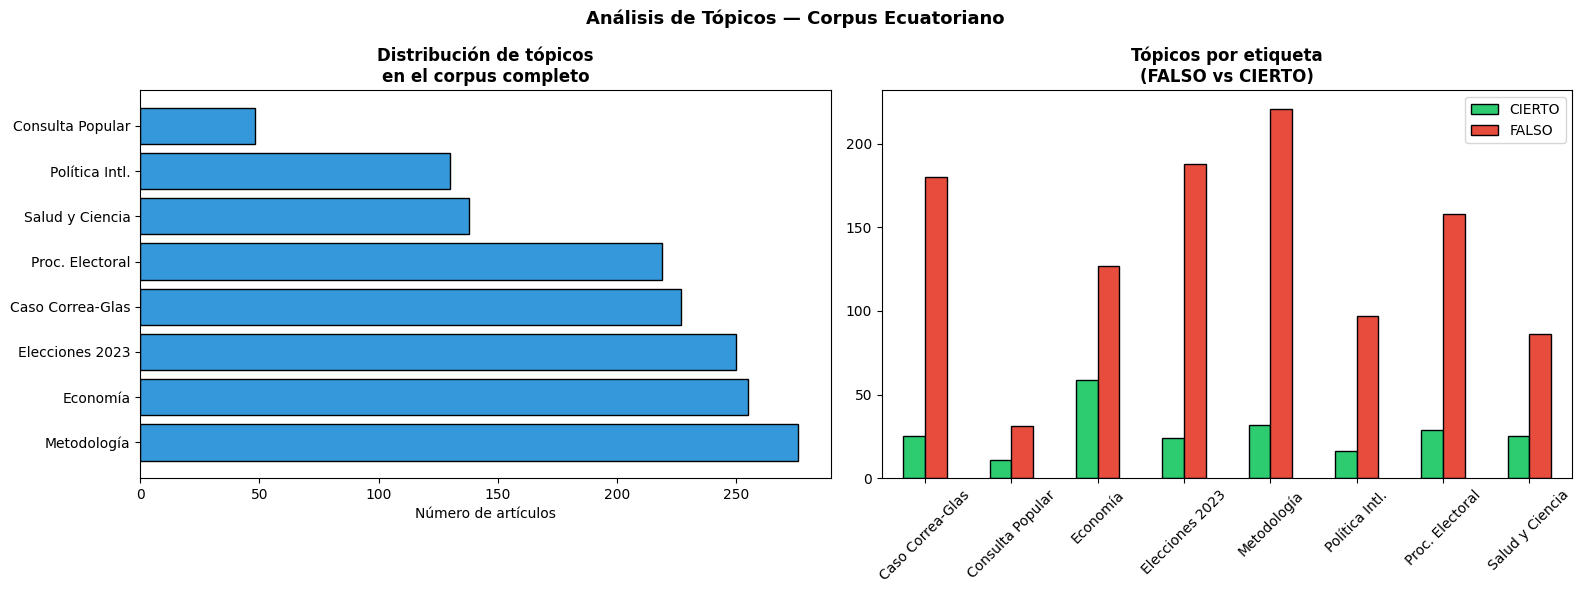

=== TÓPICOS MÁS FRECUENTES ===
topico_nombre
Metodología         276
Economía            255
Elecciones 2023     250
Caso Correa-Glas    227
Proc. Electoral     219
Salud y Ciencia     138
Política Intl.      130
Consulta Popular     48

=== TÓPICO CON MÁS DESINFORMACIÓN ===
topico_nombre
Metodología         221
Elecciones 2023     188
Caso Correa-Glas    180
Proc. Electoral     158
Economía            127
Política Intl.       97
Salud y Ciencia      86
Consulta Popular     31


In [5]:
# ================================================
# PASO 4: DISTRIBUCIÓN DE TÓPICOS POR ETIQUETA
# ================================================

# Asignar tópico dominante a cada artículo
doc_topic_matrix = lda.transform(X)
df['topico_dominante'] = doc_topic_matrix.argmax(axis=1) + 1

topico_labels = {
    1: 'Política Intl.',
    2: 'Economía',
    3: 'Elecciones 2023',
    4: 'Metodología',
    5: 'Consulta Popular',
    6: 'Caso Correa-Glas',
    7: 'Salud y Ciencia',
    8: 'Proc. Electoral'
}
df['topico_nombre'] = df['topico_dominante'].map(topico_labels)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Distribución de tópicos en todo el corpus
topic_counts = df['topico_nombre'].value_counts()
axes[0].barh(topic_counts.index, topic_counts.values,
             color='#3498DB', edgecolor='black')
axes[0].set_title('Distribución de tópicos\nen el corpus completo',
                  fontweight='bold')
axes[0].set_xlabel('Número de artículos')

# Distribución por etiqueta (FALSO vs CIERTO)
df_fc = df[df['etiqueta'].isin(['FALSO', 'CIERTO'])]
topic_etiqueta = df_fc.groupby(
    ['topico_nombre', 'etiqueta']
).size().unstack(fill_value=0)

topic_etiqueta.plot(
    kind='bar', ax=axes[1],
    color=['#2ECC71', '#E74C3C'],
    edgecolor='black'
)
axes[1].set_title('Tópicos por etiqueta\n(FALSO vs CIERTO)',
                  fontweight='bold')
axes[1].set_xlabel('')
axes[1].tick_params(axis='x', rotation=45)
axes[1].legend(['CIERTO', 'FALSO'])

plt.suptitle('Análisis de Tópicos — Corpus Ecuatoriano',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('../reports/17_lda_distribucion_topicos.png',
            dpi=150, bbox_inches='tight')
plt.show()

print("=== TÓPICOS MÁS FRECUENTES ===")
print(df['topico_nombre'].value_counts().to_string())
print(f"\n=== TÓPICO CON MÁS DESINFORMACIÓN ===")
falsos_por_topico = df[df['etiqueta']=='FALSO']['topico_nombre'].value_counts()
print(falsos_por_topico.to_string())

In [6]:
# ================================================
# PASO 5: RESUMEN FINAL
# ================================================
print("=" * 55)
print("RESUMEN — ANÁLISIS LINGÜÍSTICO CORPUS ECUATORIANO")
print("=" * 55)
print(f"Técnica:          LDA (Latent Dirichlet Allocation)")
print(f"Implementación:   sklearn — LatentDirichletAllocation")
print(f"Corpus:           Ecuador Chequea (1,500+ verificaciones)")
print(f"Número de tópicos: 8")
print(f"")
print(f"Tópicos identificados:")
print(f"  1. Política Internacional (Noboa, Trump, México)")
print(f"  2. Economía y Finanzas")
print(f"  3. Elecciones 2023 (Noboa vs González)")
print(f"  4. Metodología (TikTok, fuentes, verificación)")
print(f"  5. Consulta Popular")
print(f"  6. Caso Correa-Glas (Fiscalía, Justicia)")
print(f"  7. Salud y Ciencia")
print(f"  8. Proceso Electoral (Lasso, Asamblea)")
print(f"")
print(f"Hallazgos principales:")
print(f"  → Metodología es el tópico con más desinformación")
print(f"  → Elecciones 2023 y Caso Correa son los más desinformados")
print(f"  → Política domina 5 de 8 tópicos")
print(f"  → TikTok es el principal vector identificado")
print(f"  → Economía tiene mejor ratio FALSO/CIERTO")
print(f"")
print(f"Archivos guardados:")
print(f"  ✓ reports/16_lda_topicos_ecuador.png")
print(f"  ✓ reports/17_lda_distribucion_topicos.png")

RESUMEN — ANÁLISIS LINGÜÍSTICO CORPUS ECUATORIANO
Técnica:          LDA (Latent Dirichlet Allocation)
Implementación:   sklearn — LatentDirichletAllocation
Corpus:           Ecuador Chequea (1,500+ verificaciones)
Número de tópicos: 8

Tópicos identificados:
  1. Política Internacional (Noboa, Trump, México)
  2. Economía y Finanzas
  3. Elecciones 2023 (Noboa vs González)
  4. Metodología (TikTok, fuentes, verificación)
  5. Consulta Popular
  6. Caso Correa-Glas (Fiscalía, Justicia)
  7. Salud y Ciencia
  8. Proceso Electoral (Lasso, Asamblea)

Hallazgos principales:
  → Metodología es el tópico con más desinformación
  → Elecciones 2023 y Caso Correa son los más desinformados
  → Política domina 5 de 8 tópicos
  → TikTok es el principal vector identificado
  → Economía tiene mejor ratio FALSO/CIERTO

Archivos guardados:
  ✓ reports/16_lda_topicos_ecuador.png
  ✓ reports/17_lda_distribucion_topicos.png


In [7]:
joblib.dump(lda, '../models/lda_model.pkl')
joblib.dump(vectorizer, '../models/lda_vectorizer.pkl')
print('Modelo y vectorizador LDA guardados correctamente')

Modelo y vectorizador LDA guardados correctamente
